# Phase 2 analysis: order-flow imbalance (OFI) on IEX DEEP data

This notebook loads the processed data (`data/processed/`), explores it, and shows the first analytics results.
Every number comes from `src/analytics.py`; this notebook only calls it and draws the figures.

- Rebuild the processed data: `python src/pipeline.py`
- Rebuild every result table (CSV files in `results/`): `python src/analytics.py`
- Figures are saved to `figures/` (01 to 08).


In [ ]:
import importlib
import sys
from datetime import timedelta
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent                  
sys.path.insert(0, str(ROOT / "src"))
import analytics
importlib.reload(analytics)               

(ROOT / "figures").mkdir(exist_ok=True)
book, trades = analytics.load_processed()
print(book.shape, trades.shape)
book.head()

(7451501, 11) (39096, 10)


timestamp,bid_prices,bid_sizes,ask_prices,ask_sizes,ofi,symbol,session,mid,spread,dmid
"datetime[μs, UTC]",f64,i64,f64,i64,i64,str,str,f64,f64,f64
2026-09-11 12:00:01.118533 UTC,762.28,100,null,null,null,"""SPY""","""pre""",null,null,null
2026-09-11 12:00:01.118620 UTC,762.28,100,762.41,100,null,"""SPY""","""pre""",762.345,0.13,null
2026-09-11 12:00:01.369084 UTC,762.31,100,762.41,100,100,"""SPY""","""pre""",762.36,0.1,0.015
2026-09-11 12:00:01.517991 UTC,762.28,100,762.41,100,-100,"""SPY""","""pre""",762.345,0.13,-0.015
2026-09-11 12:00:01.628174 UTC,762.31,100,762.41,100,100,"""SPY""","""pre""",762.36,0.1,0.015


## 1. One variable: OFI per book update (SPY)

**Question:** What does the distribution of order-flow imbalance look like for a single book update?


**Interpretation :**

> *Among more than two million SPY order book updates (regular session, before 15:59), 21.75% show zero net change. This means no net pressure shifted at the best bid and ask, though deeper book levels may have still changed. The central 98% of updates fall tightly between −200 and +200 shares, while the extremes reach ±3,100.
The log-scale figure makes rare values easier to see, revealing 3,910 updates (about 0.18% of the sample) at exactly ±1,500 shares. These repeated values are investigated in Section 3, though their cause remains unknown.*

{'symbol': 'SPY', 'updates': 2219046, 'share_zero': 0.2174533560818478, 'p1': -200.0, 'p50': 0.0, 'p99': 200.0, 'p99_9': 485.0, 'min': -3100.0, 'max': 3100.0, 'rows_at_abs_1080': 51, 'rows_at_abs_1500': 3910}


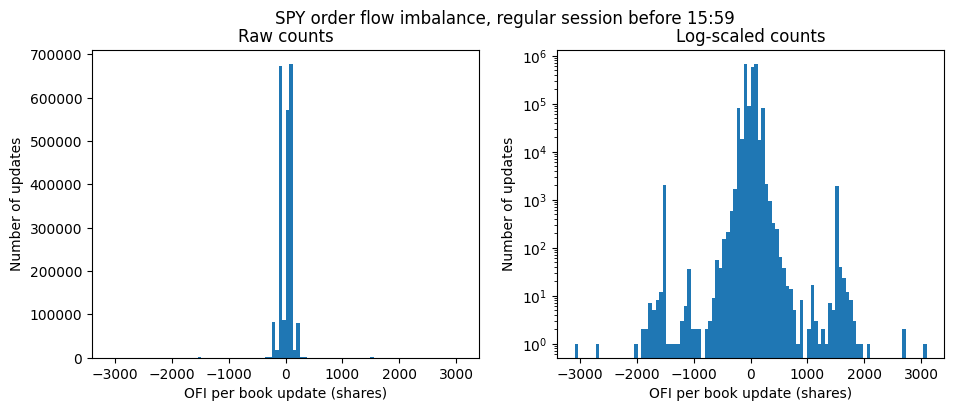

In [127]:
print(analytics.ofi_summary(book, "SPY"))

spy_ofi = (analytics.drop_closing_minute(
               book.filter((pl.col("symbol") == "SPY") & (pl.col("session") == "regular")))
           .drop_nulls("ofi")["ofi"].to_numpy())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(spy_ofi, bins=100)
ax[0].set_title("Raw counts")
ax[1].hist(spy_ofi, bins=100)
ax[1].set_yscale("log")
ax[1].set_title("Log-scaled counts")
for a in ax:
    a.set_xlabel("OFI per book update (shares)")
    a.set_ylabel("Number of updates")
fig.suptitle("SPY order flow imbalance, regular session before 15:59")
fig.savefig(ROOT / "figures" / "01_spy_ofi_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Two variables: OFI vs. price change in 1-second windows (SPY)

**Question:** When net buying pressure builds up over one second, does the mid-price rise in that same second?

### 2a. First look at all windows (closing minute still included)

windows: 23340 | rank corr: 0.5919579131734685
OFI  min/max: -31568 12606
dmid min/max: -0.7800000000000864 11.80499999999995


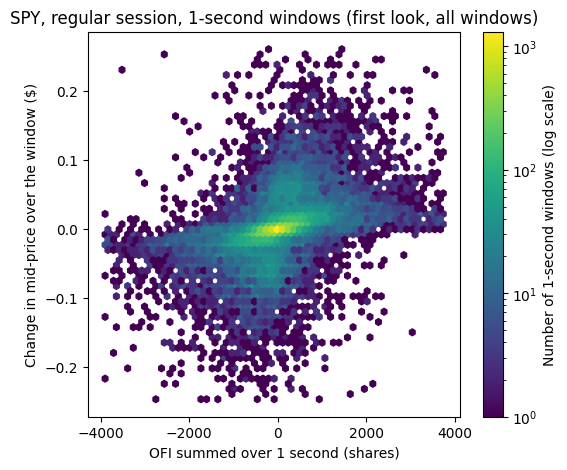

In [128]:
w_all = analytics.make_windows(book, "SPY", "1s", trim=False)    # keeps the closing minute
x_all, y_all = w_all["ofi_sum"].to_numpy(), w_all["dmid_w"].to_numpy()
print("windows:", len(w_all),
      "| rank corr:", w_all.select(pl.corr("ofi_sum", "dmid_w", method="spearman")).item())
print("OFI  min/max:", x_all.min(), x_all.max())
print("dmid min/max:", y_all.min(), y_all.max())

lx0, hx0 = np.percentile(x_all, [0.5, 99.5]); ly0, hy0 = np.percentile(y_all, [0.5, 99.5])
fig, ax = plt.subplots(figsize=(6, 5))
hb = ax.hexbin(x_all, y_all, gridsize=60, bins="log", extent=(lx0, hx0, ly0, hy0), mincnt=1)
fig.colorbar(hb, label="Number of 1-second windows (log scale)")
ax.set_xlabel("OFI summed over 1 second (shares)")
ax.set_ylabel("Change in mid-price over the window ($)")
ax.set_title("SPY, regular session, 1-second windows (first look, all windows)")
plt.show()        # first look only; the saved Figure 2 comes after the closing-minute decision

### 2b. Something odd: a very large price change

**Question:** The largest 1-second change in the mid-price is far bigger than anything else. Is it a real price move?


**Interpretation :**

> * The largest one-second mid-price jump was $11.805, occurring right at 15:59:59. Looking at the 767 book updates within that single second, the spread widens from $0.27 to $23.64, and then $23.65, pulling the midpoint up from $764.265 to $775.950. Working backward from the spread and midpoint, the bid stayed relatively flat around $764.13, meaning the best ask became a far-away order near $787.77, which is SPY’s highest quote of the day. This behavior is consistent with the nearest asks disappearing from the book, leaving a large gap, rather than the actual market value shifting by $12.We can compare a likely real move with a likely distortion by looking at Order Flow Imbalance (OFI). Shortly after the open at 09:40:36, a $1.115 price increase came with a large +11,043 share OFI. In contrast, the $11.805 closing jump happened alongside an OFI of just +2,263 shares. A huge price jump on light OFI is consistent with an empty book rather than a real rally.The final minute shows extreme OFI values overall, including the most negative one-second OFI, −31,568 shares, at 15:59:57. During the exact milliseconds of the $11.805 midpoint jump, the data shows OFI alternating between +1,080 and −1,080 shares. This pattern may be related to the repeating clusters we will explore in Section 3. *

In [129]:
pl.Config.set_tbl_cols(10)
i_big = int(w_all["dmid_w"].arg_max())
print("Largest mid-price jump, with 2 rows before and after:")
print(w_all.slice(max(i_big - 2, 0), 5))

i_low = int(w_all["ofi_sum"].arg_min())
print("\nMost negative OFI, with 2 rows before and after:")
print(w_all.slice(max(i_low - 2, 0), 5))

Largest mid-price jump, with 2 rows before and after:
shape: (3, 4)
┌─────────────────────────┬─────────┬─────────┬────────┐
│ timestamp               ┆ ofi_sum ┆ mid_end ┆ dmid_w │
│ ---                     ┆ ---     ┆ ---     ┆ ---    │
│ datetime[μs, UTC]       ┆ i64     ┆ f64     ┆ f64    │
╞═════════════════════════╪═════════╪═════════╪════════╡
│ 2026-09-11 19:59:57 UTC ┆ -31568  ┆ 764.105 ┆ -0.105 │
│ 2026-09-11 19:59:58 UTC ┆ -13878  ┆ 764.14  ┆ 0.035  │
│ 2026-09-11 19:59:59 UTC ┆ 2263    ┆ 775.945 ┆ 11.805 │
└─────────────────────────┴─────────┴─────────┴────────┘

Most negative OFI, with 2 rows before and after:
shape: (5, 4)
┌─────────────────────────┬─────────┬─────────┬────────┐
│ timestamp               ┆ ofi_sum ┆ mid_end ┆ dmid_w │
│ ---                     ┆ ---     ┆ ---     ┆ ---    │
│ datetime[μs, UTC]       ┆ i64     ┆ f64     ┆ f64    │
╞═════════════════════════╪═════════╪═════════╪════════╡
│ 2026-09-11 19:59:55 UTC ┆ -4303   ┆ 764.325 ┆ 0.0    │
│ 2026-09-11 

In [130]:
t_big = w_all["timestamp"][i_big]
raw = (book.filter((pl.col("symbol") == "SPY")
                   & (pl.col("timestamp") >= t_big)
                   & (pl.col("timestamp") < t_big + timedelta(seconds=1)))
           .select("timestamp", "ofi", "mid", "spread"))
pl.Config.set_tbl_rows(20)
print(len(raw), "book states in that second")
print(raw.tail(10))
print(raw.select(pl.col("mid").max(), pl.col("spread").max()))
print(raw.filter(pl.col("mid") > 770).head(5))

767 book states in that second
shape: (10, 4)
┌────────────────────────────────┬───────┬─────────┬────────┐
│ timestamp                      ┆ ofi   ┆ mid     ┆ spread │
│ ---                            ┆ ---   ┆ ---     ┆ ---    │
│ datetime[μs, UTC]              ┆ i64   ┆ f64     ┆ f64    │
╞════════════════════════════════╪═══════╪═════════╪════════╡
│ 2026-09-11 19:59:59.991511 UTC ┆ 100   ┆ 764.185 ┆ 0.03   │
│ 2026-09-11 19:59:59.991645 UTC ┆ 200   ┆ 764.27  ┆ 0.2    │
│ 2026-09-11 19:59:59.991891 UTC ┆ -100  ┆ 764.26  ┆ 0.22   │
│ 2026-09-11 19:59:59.992074 UTC ┆ 1080  ┆ 764.265 ┆ 0.23   │
│ 2026-09-11 19:59:59.993092 UTC ┆ 1080  ┆ 764.27  ┆ 0.24   │
│ 2026-09-11 19:59:59.995128 UTC ┆ -1080 ┆ 764.265 ┆ 0.25   │
│ 2026-09-11 19:59:59.996154 UTC ┆ 1080  ┆ 764.27  ┆ 0.26   │
│ 2026-09-11 19:59:59.997168 UTC ┆ -1080 ┆ 764.265 ┆ 0.27   │
│ 2026-09-11 19:59:59.998188 UTC ┆ 1080  ┆ 775.95  ┆ 23.64  │
│ 2026-09-11 19:59:59.999208 UTC ┆ -1080 ┆ 775.945 ┆ 23.65  │
└───────────────────────

In [131]:
w_ny = w_all.with_columns(pl.col("timestamp").dt.convert_time_zone("America/New_York").alias("ny"))
print(w_ny.sort(pl.col("dmid_w").abs(), descending=True).select("ny", "ofi_sum", "dmid_w").head(10))
print(w_ny.sort(pl.col("ofi_sum").abs(), descending=True).select("ny", "ofi_sum", "dmid_w").head(10))

shape: (10, 3)
┌────────────────────────────────┬─────────┬────────┐
│ ny                             ┆ ofi_sum ┆ dmid_w │
│ ---                            ┆ ---     ┆ ---    │
│ datetime[μs, America/New_York] ┆ i64     ┆ f64    │
╞════════════════════════════════╪═════════╪════════╡
│ 2026-09-11 15:59:59 EDT        ┆ 2263    ┆ 11.805 │
│ 2026-09-11 09:40:36 EDT        ┆ 11043   ┆ 1.115  │
│ 2026-09-11 09:30:56 EDT        ┆ 1305    ┆ 0.8    │
│ 2026-09-11 09:31:45 EDT        ┆ -1575   ┆ -0.78  │
│ 2026-09-11 09:33:45 EDT        ┆ -560    ┆ -0.78  │
│ 2026-09-11 09:30:13 EDT        ┆ -1675   ┆ 0.755  │
│ 2026-09-11 09:33:22 EDT        ┆ -422    ┆ -0.735 │
│ 2026-09-11 09:33:41 EDT        ┆ -1120   ┆ -0.725 │
│ 2026-09-11 09:31:35 EDT        ┆ -190    ┆ -0.715 │
│ 2026-09-11 09:34:19 EDT        ┆ -1550   ┆ -0.715 │
└────────────────────────────────┴─────────┴────────┘
shape: (10, 3)
┌────────────────────────────────┬─────────┬────────┐
│ ny                             ┆ ofi_sum ┆ dmid_w 

### 2c. Decision: drop the closing minute (15:59 New York time onward) from the window analysis


**Why this decision:**

> * To avoid the distorted closing quotes and unreliable midpoints, the final minute (15:59 ET onward) is excluded from the window analysis. This removes 60 windows, reducing the sample from 23,340 to 23,280, and brings the maximum absolute price change down from $11.805 to $1.115. The core relationship holds steady without this data. The Spearman correlation barely shifts, from 0.591958 to 0.591861, and the robust slope moves from 2.0779 to 2.0896 cents per 1,000 shares of OFI. This suggests that the positive association between OFI and price changes is not driven by the closing anomaly. Dropping the entire final minute is a blunt but transparent cutoff. It may remove some valid observations and does not guarantee that the rest of the day is clean, but it does not change the result.*

In [132]:
print(analytics.trim_effect(book))

shape: (2, 5)
┌───────────────┬─────────┬──────────┬──────────────┬───────────────────────┐
│ version       ┆ windows ┆ spearman ┆ max_abs_dmid ┆ cents_per_1000_shares │
│ ---           ┆ ---     ┆ ---      ┆ ---          ┆ ---                   │
│ str           ┆ i64     ┆ f64      ┆ f64          ┆ f64                   │
╞═══════════════╪═════════╪══════════╪══════════════╪═══════════════════════╡
│ with_close    ┆ 23340   ┆ 0.591958 ┆ 11.805       ┆ 2.077922              │
│ without_close ┆ 23280   ┆ 0.591861 ┆ 1.115        ┆ 2.089552              │
└───────────────┴─────────┴──────────┴──────────────┴───────────────────────┘


### 2d. Robust line and residuals (closing minute dropped)

**Interpretation :**

> *Across the 23,280 retained windows, OFI and mid-price changes show a Spearman correlation of 0.592. Positive OFI generally moves with rising prices, and negative OFI with falling prices. Keep in mind that this is a simultaneous relationship, not a predictive signal, and a 0.592 correlation does not mean OFI explains 59.2% of price variance. A Theil–Sen line, fitted on a random sample of 5,000 windows, gives a slope of 2.09 cents per 1,000 shares of OFI (bounded between 2.00 and 2.19 cents), with a zero intercept. Practically, a net imbalance of +1,000 shares goes with a +$0.0209 change in the mid-price. While the plot crops out about 1.98% of the most extreme windows for visual clarity, they are still included in the correlation. The residuals show that this straight line fits the center well but misses more at the extremes. The median error is zero, and the middle 50% of residuals are tight, between −1.08 and +1.09 cents. However, the tails are wide, with the 1st and 99th percentiles at −16.45 and +16.12 cents. Furthermore, the line seems to overshoot at large imbalances. Near ±2,000 shares, the median residual moves away from zero, which suggests the 2.09-cent slope is somewhat too steep at the outer edges. The line captures the core trend, but its predicted changes are too large by roughly 1.5 to 1.7 cents when the book is heavily skewed.*

windows: 23280 | rank corr: 0.5918607996435273
{'slope': 2.0895522388040698e-05, 'intercept': 0.0, 'slope_lo': 1.9973368841677822e-05, 'slope_hi': 2.1897810218958186e-05}
cents per 1,000 shares of OFI: 2.0895522388040697
share outside plot box: 0.019759450171821305


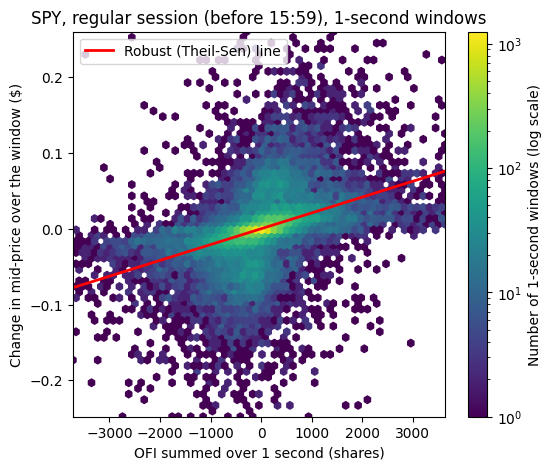

In [133]:
w = analytics.make_windows(book, "SPY", "1s")          # closing minute dropped
x, y = w["ofi_sum"].to_numpy(), w["dmid_w"].to_numpy()
fit = analytics.robust_fit(x, y)
print("windows:", len(w),
      "| rank corr:", w.select(pl.corr("ofi_sum", "dmid_w", method="spearman")).item())
print({k: fit[k] for k in ("slope", "intercept", "slope_lo", "slope_hi")})
print("cents per 1,000 shares of OFI:", fit["slope"] * 1000 * 100)

lx, hx = np.percentile(x, [0.5, 99.5]); ly, hy = np.percentile(y, [0.5, 99.5])
print("share outside plot box:", ((x < lx) | (x > hx) | (y < ly) | (y > hy)).mean())

fig, ax = plt.subplots(figsize=(6, 5))
hb = ax.hexbin(x, y, gridsize=60, bins="log", extent=(lx, hx, ly, hy), mincnt=1)
fig.colorbar(hb, label="Number of 1-second windows (log scale)")
xs = np.array([lx, hx])
ax.plot(xs, fit["slope"] * xs + fit["intercept"], color="red", lw=2, label="Robust (Theil-Sen) line")
ax.set_xlim(lx, hx); ax.set_ylim(ly, hy)
ax.set_xlabel("OFI summed over 1 second (shares)")
ax.set_ylabel("Change in mid-price over the window ($)")
ax.set_title("SPY, regular session (before 15:59), 1-second windows")
ax.legend(loc="upper left")
fig.savefig(ROOT / "figures" / "02_spy_ofi_vs_dmid_1s.png", dpi=150, bbox_inches="tight")
plt.show()

shape: (5, 2)
┌────────────┬───────────┐
│ percentile ┆ residual  │
│ ---        ┆ ---       │
│ i64        ┆ f64       │
╞════════════╪═══════════╡
│ 1          ┆ -0.164492 │
│ 25         ┆ -0.010766 │
│ 50         ┆ 0.0       │
│ 75         ┆ 0.010851  │
│ 99         ┆ 0.161204  │
└────────────┴───────────┘


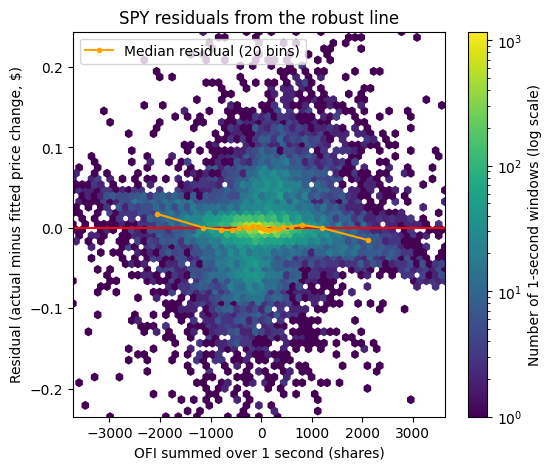

In [134]:
resid, pct_table, bin_table = analytics.residual_summary(x, y, fit)
print(pct_table)

lr, hr = np.percentile(resid, [0.5, 99.5])
fig, ax = plt.subplots(figsize=(6, 5))
hb = ax.hexbin(x, resid, gridsize=60, bins="log", extent=(lx, hx, lr, hr), mincnt=1)
fig.colorbar(hb, label="Number of 1-second windows (log scale)")
ax.axhline(0, color="red", lw=1.5)
ax.plot(bin_table["median_ofi"].to_numpy(), bin_table["median_residual"].to_numpy(),
        color="orange", marker="o", ms=3, label="Median residual (20 bins)")
ax.set_xlim(lx, hx); ax.set_ylim(lr, hr)
ax.set_xlabel("OFI summed over 1 second (shares)")
ax.set_ylabel("Residual (actual minus fitted price change, $)")
ax.set_title("SPY residuals from the robust line")
ax.legend(loc="upper left")
fig.savefig(ROOT / "figures" / "03_spy_ofi_residuals_1s.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Unexpected clusters in OFI

**Question:** The log-scale histogram shows small isolated clusters. What are they and when do they happen?

**Interpretation :**

> *Zooming in on the repeated clusters, there are exactly 360 updates at ±1,080 shares (242 negative, 118 positive) and 4,514 at ±1,500 shares (2,285 negative, 2,229 positive). Both sizes are concentrated late in the day. In the wider 1,050–1,120 band, all 380 observations happen during the 15:00 hour. The 1,450–1,550 band shows a similar late-day pattern: just 17 updates in the 11:00 hour and 518 at 14:00, rising to 4,014 in the 15:00 hour. While these clusters are consistent with someone repeatedly adding, removing, or exposing identical quote sizes, the histogram alone cannot prove who is doing this or why.Note that this section includes the final minute of the trading day. If we exclude that final minute, as we did in the window analysis, the ±1,500 count drops from 4,514 to 3,910, but the ±1,080 count falls from 360 to just 51. So most of the ±1,080 cluster (309 of 360) lies in the final minute, which also contains the ±1,080 toggling we saw during the large closing price jump, while most of the ±1,500 cluster does not.*

In [135]:
spy_reg = book.filter((pl.col("symbol") == "SPY") & (pl.col("session") == "regular"))
for lo_, hi_ in [(1050, 1120), (1450, 1550)]:
    near = spy_reg.filter(pl.col("ofi").abs().is_between(lo_, hi_))
    print(f"--- |OFI| between {lo_} and {hi_} ---")
    print(near["ofi"].value_counts(sort=True).head(8))
    by_hour = near.with_columns(
        pl.col("timestamp").dt.convert_time_zone("America/New_York").dt.hour().alias("hour"))
    print(by_hour["hour"].value_counts().sort("hour"))

--- |OFI| between 1050 and 1120 ---
shape: (8, 2)
┌───────┬───────┐
│ ofi   ┆ count │
│ ---   ┆ ---   │
│ i64   ┆ u32   │
╞═══════╪═══════╡
│ -1080 ┆ 242   │
│ 1080  ┆ 118   │
│ -1120 ┆ 8     │
│ 1116  ┆ 2     │
│ -1108 ┆ 2     │
│ -1078 ┆ 2     │
│ -1068 ┆ 2     │
│ 1060  ┆ 1     │
└───────┴───────┘
shape: (1, 2)
┌──────┬───────┐
│ hour ┆ count │
│ ---  ┆ ---   │
│ i8   ┆ u32   │
╞══════╪═══════╡
│ 15   ┆ 380   │
└──────┴───────┘
--- |OFI| between 1450 and 1550 ---
shape: (8, 2)
┌───────┬───────┐
│ ofi   ┆ count │
│ ---   ┆ ---   │
│ i64   ┆ u32   │
╞═══════╪═══════╡
│ -1500 ┆ 2285  │
│ 1500  ┆ 2229  │
│ 1540  ┆ 9     │
│ -1540 ┆ 2     │
│ 1495  ┆ 2     │
│ 1499  ┆ 2     │
│ 1480  ┆ 2     │
│ 1497  ┆ 2     │
└───────┴───────┘
shape: (3, 2)
┌──────┬───────┐
│ hour ┆ count │
│ ---  ┆ ---   │
│ i8   ┆ u32   │
╞══════╪═══════╡
│ 11   ┆ 17    │
│ 14   ┆ 518   │
│ 15   ┆ 4014  │
└──────┴───────┘


## 4. Window length and liquidity tier

**Question:** Does the OFI-price relationship change with the window length (1 second, 10 seconds, 1 minute), and does it differ between the high-activity ETFs (SPY, QQQ, IWM) and the thin ones (EMB, VCSH)?

**Interpretation :**

> *The OFI-price link depends on both the symbol and the window length. For SPY, QQQ and IWM it is strongest at one second and weakens with longer windows (SPY 0.592 to 0.447, QQQ 0.527 to 0.085, IWM 0.843 to 0.715), and the fitted slopes shrink too (QQQ’s one-minute slope of 0.0913 cents per 1,000 shares has an interval that reaches zero). IWM has the highest correlation but the smallest slope of the three at one and ten seconds, so a tight link does not mean a large price response, and raw-share slopes can’t be compared as economic impact across ETFs. EMB and VCSH go the other way (EMB 0.430 to 0.865, VCSH 0.251 to 0.581) because most of their short windows show no price change (89.3% and 96.7% at one second), which forces the median-based slope to zero. This data can’t explain why QQQ fades so fast or why IWM is stronger than SPY, and the sample shrinks from 6,859–23,338 windows at one second to 388 at one minute.*

shape: (15, 8)
┌────────┬────────┬───────────┬──────────┬─────────────────┬─────────────────────┬────────┬────────┐
│ symbol ┆ window ┆ n_windows ┆ spearman ┆ share_dmid_zero ┆ cents_per_1000_shar ┆ lo     ┆ hi     │
│ ---    ┆ ---    ┆ ---       ┆ ---      ┆ ---             ┆ es                  ┆ ---    ┆ ---    │
│ str    ┆ str    ┆ i64       ┆ f64      ┆ f64             ┆ ---                 ┆ f64    ┆ f64    │
│        ┆        ┆           ┆          ┆                 ┆ f64                 ┆        ┆        │
╞════════╪════════╪═══════════╪══════════╪═════════════════╪═════════════════════╪════════╪════════╡
│ SPY    ┆ 1s     ┆ 23280     ┆ 0.592    ┆ 0.184           ┆ 2.0896              ┆ 1.9973 ┆ 2.1898 │
│ SPY    ┆ 10s    ┆ 2333      ┆ 0.539    ┆ 0.041           ┆ 1.3253              ┆ 1.2337 ┆ 1.4188 │
│ SPY    ┆ 1m     ┆ 388       ┆ 0.447    ┆ 0.01            ┆ 0.8376              ┆ 0.6739 ┆ 1.0055 │
│ QQQ    ┆ 1s     ┆ 23338     ┆ 0.527    ┆ 0.127           ┆ 1.4925         

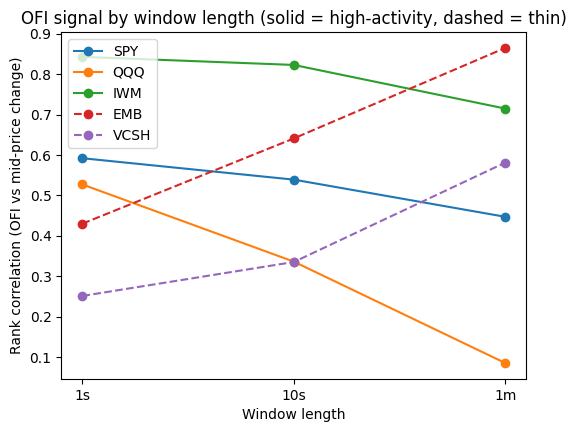

In [136]:
res = analytics.window_table(book)
pl.Config.set_tbl_rows(20); pl.Config.set_tbl_cols(10)
print(res)

fig, ax = plt.subplots(figsize=(6, 4.5))
for sym in analytics.SYMBOLS:
    d_sym = res.filter(pl.col("symbol") == sym)
    vals = [d_sym.filter(pl.col("window") == o)["spearman"].item() for o in analytics.WINDOWS]
    ax.plot(analytics.WINDOWS, vals, marker="o", label=sym,
            ls="-" if sym in ("SPY", "QQQ", "IWM") else "--")
ax.set_xlabel("Window length")
ax.set_ylabel("Rank correlation (OFI vs mid-price change)")
ax.set_title("OFI signal by window length (solid = high-activity, dashed = thin)")
ax.legend()
fig.savefig(ROOT / "figures" / "04_spearman_by_window.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Quote activity: book updates per trade, across the day, and missing seconds

**Questions:** How many book updates happen for each executed trade, and how does that differ by symbol and session? When in the day is the activity? Which seconds of the regular session have no quote data at all?


**Interpretation :**

> *In the regular session, book updates far outnumber trades: QQQ has 398.8 updates per trade, IWM 190.5, SPY 119.1, VCSH 67.5 and EMB 55.9. These ratios compare quote activity with executions; they are not cancellation rates or counts of separate orders. Before the open and after the close the ratios swing much more (SPY 357.7 and 93.2, QQQ 620.4 and 357.4, IWM 13.8 and 71.0), but each rests on only 13 to 98 trades, and EMB and VCSH have no trades in those sessions, so their ratios are undefined rather than zero. Activity jumps at the open, slows through the day and picks up near the close, and EMB and VCSH are far quieter than the other three: they have at least one update in only 53.5% and 29.5% of regular-session seconds (against 99.7% for SPY, about 100% for QQQ and 99.1% for IWM), falling to about 39% and 22–25% later in the day. A second with no update is not necessarily missing data, since the book may simply have stayed the same, but it means EMB and VCSH windows cover a smaller and busier part of the day, so their window results should be read with that in mind.*

shape: (15, 5)
┌────────┬─────────┬─────────┬────────┬──────────────────┐
│ symbol ┆ session ┆ quotes  ┆ trades ┆ quotes_per_trade │
│ ---    ┆ ---     ┆ ---     ┆ ---    ┆ ---              │
│ str    ┆ str     ┆ u32     ┆ u32    ┆ f64              │
╞════════╪═════════╪═════════╪════════╪══════════════════╡
│ EMB    ┆ after   ┆ 3       ┆ null   ┆ null             │
│ EMB    ┆ pre     ┆ 352     ┆ null   ┆ null             │
│ EMB    ┆ regular ┆ 92818   ┆ 1661   ┆ 55.9             │
│ IWM    ┆ after   ┆ 1633    ┆ 23     ┆ 71.0             │
│ IWM    ┆ pre     ┆ 180     ┆ 13     ┆ 13.8             │
│ IWM    ┆ regular ┆ 1973381 ┆ 10358  ┆ 190.5            │
│ QQQ    ┆ after   ┆ 17157   ┆ 48     ┆ 357.4            │
│ QQQ    ┆ pre     ┆ 60799   ┆ 98     ┆ 620.4            │
│ QQQ    ┆ regular ┆ 3010264 ┆ 7548   ┆ 398.8            │
│ SPY    ┆ after   ┆ 2422    ┆ 26     ┆ 93.2             │
│ SPY    ┆ pre     ┆ 23606   ┆ 66     ┆ 357.7            │
│ SPY    ┆ regular ┆ 2236684 ┆ 18779  ┆ 1

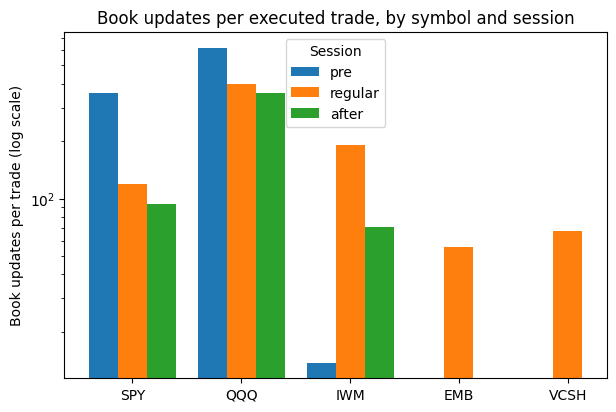

In [137]:
qt = analytics.quote_trade_table(book, trades)
print(qt)

syms = analytics.SYMBOLS
sess = ["pre", "regular", "after"]
bw = 0.8 / len(sess)
fig, ax = plt.subplots(figsize=(7, 4.5))
for j, s in enumerate(sess):
    vals = []
    for sym in syms:
        r = qt.filter((pl.col("symbol") == sym) & (pl.col("session") == s))["quotes_per_trade"]
        vals.append(r.item() if len(r) and r.item() is not None else float("nan"))
    ax.bar(np.arange(len(syms)) + j * bw, vals, width=bw, label=s)
ax.set_xticks(np.arange(len(syms)) + bw * (len(sess) - 1) / 2)
ax.set_xticklabels(syms)
ax.set_yscale("log")
ax.set_ylabel("Book updates per trade (log scale)")
ax.set_title("Book updates per executed trade, by symbol and session")
ax.legend(title="Session")
fig.savefig(ROOT / "figures" / "05_quotes_per_trade.png", dpi=150, bbox_inches="tight")
plt.show()

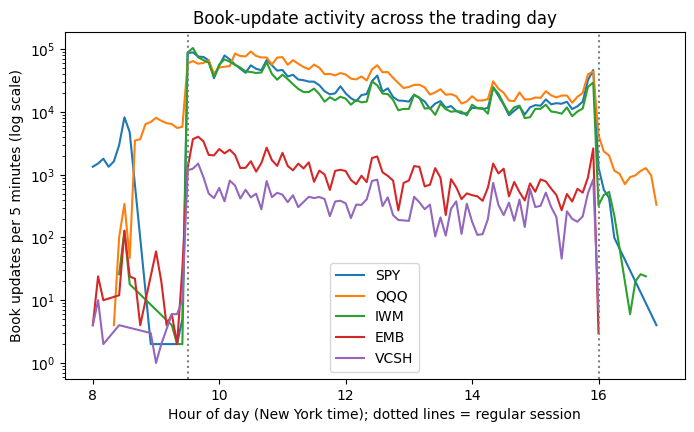

In [138]:
act = analytics.activity_by_time(book)

fig, ax = plt.subplots(figsize=(8, 4.5))
for sym in syms:
    dd = act.filter(pl.col("symbol") == sym)
    ax.plot(dd["hr"].to_numpy(), dd["n"].to_numpy(), label=sym)
ax.set_yscale("log")
ax.axvline(9.5, color="gray", ls=":"); ax.axvline(16, color="gray", ls=":")
ax.set_xlabel("Hour of day (New York time); dotted lines = regular session")
ax.set_ylabel("Book updates per 5 minutes (log scale)")
ax.set_title("Book-update activity across the trading day")
ax.legend()
fig.savefig(ROOT / "figures" / "06_activity_by_time.png", dpi=150, bbox_inches="tight")
plt.show()

shape: (5, 3)
┌────────┬───────┬──────────────────┐
│ symbol ┆ secs  ┆ share_of_seconds │
│ ---    ┆ ---   ┆ ---              │
│ str    ┆ u32   ┆ f64              │
╞════════╪═══════╪══════════════════╡
│ EMB    ┆ 12514 ┆ 0.535            │
│ IWM    ┆ 23193 ┆ 0.991            │
│ QQQ    ┆ 23399 ┆ 1.0              │
│ SPY    ┆ 23341 ┆ 0.997            │
│ VCSH   ┆ 6899  ┆ 0.295            │
└────────┴───────┴──────────────────┘


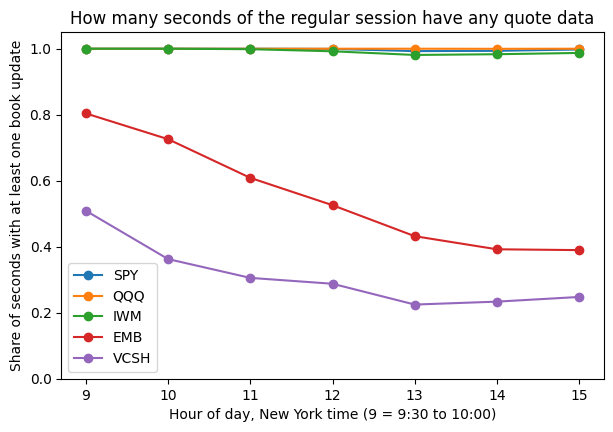

In [139]:
overall, by_hour = analytics.coverage_tables(book)
print(overall)

fig, ax = plt.subplots(figsize=(7, 4.5))
for sym in syms:
    dd = by_hour.filter(pl.col("symbol") == sym)
    ax.plot(dd["hour"].to_numpy(), dd["share"].to_numpy(), marker="o", label=sym)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Hour of day, New York time (9 = 9:30 to 10:00)")
ax.set_ylabel("Share of seconds with at least one book update")
ax.set_title("How many seconds of the regular session have any quote data")
ax.legend()
fig.savefig(ROOT / "figures" / "07_second_coverage.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. First analytics: does OFI before a trade predict the trade's side?

**Question (main research question):** Does the order-flow imbalance in the second before a trade predict whether that trade is a buy or a sell?

**How the test works:**
- A trade is a *buy* if its price is above the quote midpoint just before it, a *sell* if below; trades exactly at the midpoint are not classified.
- The feature is OFI summed over the second before the trade, using only book states strictly before it (no look-ahead).
- The score is how often the sign of that OFI matches the trade's side, compared with always guessing the more common side (the baseline).


**Interpretation :**

> *For SPY, QQQ and IWM, the one-second OFI sign does not guess the next trade’s side better than simply picking the more common side: SPY 44.6% vs. 52.6% (10,065 trades), QQQ 48.7% vs. 59.6% (4,080) and IWM 49.7% vs. 55.6% (6,323), with 95% margins of about ±1.0 to ±1.5 points. EMB looks better (60.3% vs. 53.0%, 464 trades, ±4.5 points) and VCSH looks worse (56.5% vs. 59.5%, 115 trades, ±9.1 points), but we don’t trust either result yet: the baseline uses all classified trades while the hit rate leaves out trades with zero OFI (35.3% of EMB and 47.7% of VCSH), so the baseline needs recomputing on the same trades. Using a 1 ms OFI window raises the hit rate (SPY 44.6% to 55.7%, EMB 60.3% to 80.4%) but on far fewer trades, and leaving a 10 to 500 ms gap before the trade drops EMB to between 52.5% and 47.5%, so whatever signal exists sits right next to the trade. Overall, OFI lines up with price changes within the same window but is not a reliable predictor of the next trade, and with one day of data, inferred trade sides and small samples for the thin ETFs, we treat these results as exploratory.*

In [140]:
b, b_start, t = analytics.prepare_trades(book, trades)       # usable trades only
d = analytics.label_trades(t, b, b_start, window_ms=1000)
pl.Config.set_tbl_cols(12)
print(analytics.direction_table(t, d))

/Users/admin/Documents/DIC_PROJECT/src/analytics.py:184: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  return (t2.join_asof(b, on="timestamp", by="symbol", strategy="backward", allow_exact_matches=False)


shape: (5, 9)
┌────────┬──────────┬───────────┬───────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ symbol ┆ n_usable ┆ n_classif ┆ share_buy ┆ share_of ┆ hit_rate ┆ n_scored ┆ baseline ┆ margin_9 │
│ ---    ┆ ---      ┆ ied       ┆ s         ┆ i_zero   ┆ ---      ┆ ---      ┆ ---      ┆ 5        │
│ str    ┆ u32      ┆ ---       ┆ ---       ┆ ---      ┆ f64      ┆ u32      ┆ f64      ┆ ---      │
│        ┆          ┆ u32       ┆ f64       ┆ f64      ┆          ┆          ┆          ┆ f64      │
╞════════╪══════════╪═══════════╪═══════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ EMB    ┆ 1237     ┆ 717       ┆ 0.53      ┆ 0.353    ┆ 0.603    ┆ 464      ┆ 0.53     ┆ 0.045    │
│ IWM    ┆ 7963     ┆ 6392      ┆ 0.444     ┆ 0.011    ┆ 0.497    ┆ 6323     ┆ 0.556    ┆ 0.012    │
│ QQQ    ┆ 4564     ┆ 4109      ┆ 0.404     ┆ 0.007    ┆ 0.487    ┆ 4080     ┆ 0.596    ┆ 0.015    │
│ SPY    ┆ 12139    ┆ 10158     ┆ 0.526     ┆ 0.009    ┆ 0.446    ┆ 10065    

In [141]:
print(analytics.label_check(d, b))

/Users/admin/Documents/DIC_PROJECT/src/analytics.py:213: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  after = (d.select("symbol", "timestamp", "dir", "mid_before")


shape: (10, 4)
┌────────┬──────┬────────────────────────┬──────┐
│ symbol ┆ dir  ┆ avg_mid_change_next_1s ┆ len  │
│ ---    ┆ ---  ┆ ---                    ┆ ---  │
│ str    ┆ f64  ┆ f64                    ┆ u32  │
╞════════╪══════╪════════════════════════╪══════╡
│ EMB    ┆ -1.0 ┆ -0.0033                ┆ 337  │
│ EMB    ┆ 1.0  ┆ 0.0054                 ┆ 380  │
│ IWM    ┆ -1.0 ┆ 0.0011                 ┆ 3554 │
│ IWM    ┆ 1.0  ┆ 0.0159                 ┆ 2838 │
│ QQQ    ┆ -1.0 ┆ -0.0142                ┆ 2447 │
│ QQQ    ┆ 1.0  ┆ 0.0265                 ┆ 1662 │
│ SPY    ┆ -1.0 ┆ -0.0225                ┆ 4817 │
│ SPY    ┆ 1.0  ┆ 0.0176                 ┆ 5341 │
│ VCSH   ┆ -1.0 ┆ 0.0178                 ┆ 131  │
│ VCSH   ┆ 1.0  ┆ 0.1498                 ┆ 89   │
└────────┴──────┴────────────────────────┴──────┘


In [142]:
out = analytics.hit_by_window(t, b, b_start)
print(out)
out2 = analytics.hit_by_gap(d, b)
print(out2)

shape: (5, 9)
┌────────┬────────────┬──────────┬───────────┬─────────┬──────────┬────────┬─────────┬───────┐
│ symbol ┆ hit_1000ms ┆ n_1000ms ┆ hit_100ms ┆ n_100ms ┆ hit_10ms ┆ n_10ms ┆ hit_1ms ┆ n_1ms │
│ ---    ┆ ---        ┆ ---      ┆ ---       ┆ ---     ┆ ---      ┆ ---    ┆ ---     ┆ ---   │
│ str    ┆ f64        ┆ u32      ┆ f64       ┆ u32     ┆ f64      ┆ u32    ┆ f64     ┆ u32   │
╞════════╪════════════╪══════════╪═══════════╪═════════╪══════════╪════════╪═════════╪═══════╡
│ EMB    ┆ 0.603      ┆ 464      ┆ 0.716     ┆ 282     ┆ 0.78     ┆ 209    ┆ 0.804   ┆ 138   │
│ IWM    ┆ 0.497      ┆ 6323     ┆ 0.497     ┆ 5675    ┆ 0.569    ┆ 4004   ┆ 0.618   ┆ 2248  │
│ QQQ    ┆ 0.487      ┆ 4080     ┆ 0.459     ┆ 3705    ┆ 0.466    ┆ 2398   ┆ 0.507   ┆ 1233  │
│ SPY    ┆ 0.446      ┆ 10065    ┆ 0.458     ┆ 8839    ┆ 0.503    ┆ 6045   ┆ 0.557   ┆ 3442  │
│ VCSH   ┆ 0.565      ┆ 115      ┆ 0.584     ┆ 89      ┆ 0.603    ┆ 73     ┆ 0.364   ┆ 44    │
└────────┴────────────┴──────────┴──

/Users/admin/Documents/DIC_PROJECT/src/analytics.py:245: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  g = (d.select("symbol", "timestamp", "dir", "cum_start")


shape: (5, 7)
┌────────┬─────────────┬───────────┬──────────────┬────────────┬──────────────┬────────────┐
│ symbol ┆ hit_gap10ms ┆ n_gap10ms ┆ hit_gap100ms ┆ n_gap100ms ┆ hit_gap500ms ┆ n_gap500ms │
│ ---    ┆ ---         ┆ ---       ┆ ---          ┆ ---        ┆ ---          ┆ ---        │
│ str    ┆ f64         ┆ u32       ┆ f64          ┆ u32        ┆ f64          ┆ u32        │
╞════════╪═════════════╪═══════════╪══════════════╪════════════╪══════════════╪════════════╡
│ EMB    ┆ 0.525       ┆ 400       ┆ 0.517        ┆ 360        ┆ 0.475        ┆ 278        │
│ IWM    ┆ 0.487       ┆ 6292      ┆ 0.481        ┆ 6224       ┆ 0.508        ┆ 5920       │
│ QQQ    ┆ 0.491       ┆ 4069      ┆ 0.493        ┆ 4062       ┆ 0.51         ┆ 3980       │
│ SPY    ┆ 0.448       ┆ 10048     ┆ 0.473        ┆ 9976       ┆ 0.496        ┆ 9679       │
│ VCSH   ┆ 0.558       ┆ 77        ┆ 0.558        ┆ 77         ┆ 0.487        ┆ 39         │
└────────┴─────────────┴───────────┴──────────────┴─────

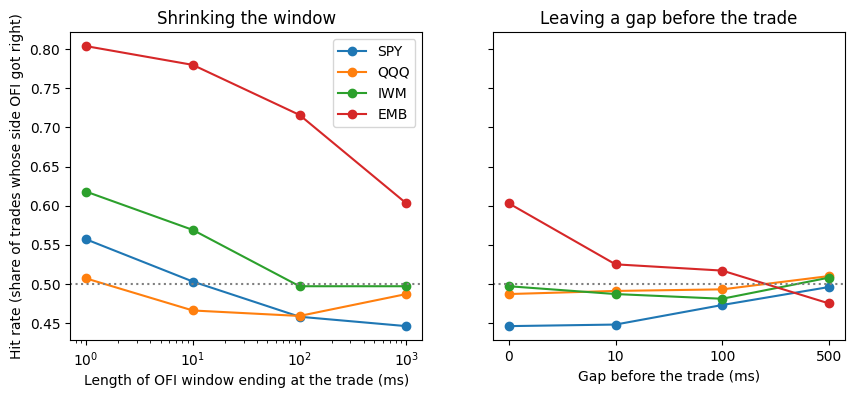

In [143]:
show = ["SPY", "QQQ", "IWM", "EMB"]          # VCSH left out: fewer than 120 scored trades
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for sym in show:
    r = out.filter(pl.col("symbol") == sym)
    r2 = out2.filter(pl.col("symbol") == sym)
    lens = [1, 10, 100, 1000]
    a1.plot(lens, [r[f"hit_{m}ms"].item() for m in lens], marker="o", label=sym)
    vals = [r["hit_1000ms"].item()] + [r2[f"hit_gap{g}ms"].item() for g in [10, 100, 500]]
    a2.plot(range(4), vals, marker="o", label=sym)
for a in (a1, a2):
    a.axhline(0.5, color="gray", ls=":")
a1.set_xscale("log")
a1.set_xlabel("Length of OFI window ending at the trade (ms)")
a2.set_xticks(range(4)); a2.set_xticklabels(["0", "10", "100", "500"])
a2.set_xlabel("Gap before the trade (ms)")
a1.set_ylabel("Hit rate (share of trades whose side OFI got right)")
a1.set_title("Shrinking the window"); a2.set_title("Leaving a gap before the trade")
a1.legend()
fig.savefig(ROOT / "figures" / "08_hit_rate_by_gap.png", dpi=150, bbox_inches="tight")
plt.show()

### 6b. Check: do the trade results change if the closing minute is dropped?

The window analysis drops 15:59 onward. This repeats the next-trade test with the same cutoff on the trades.

**conclusion :**

> *Excluding the closing minute leaves the conclusion unchanged for the high-activity ETFs. SPY (43.9% vs. 53.3% baseline), QQQ (48.4% vs. 59.7%), and IWM (49.8% vs. 56.1%) still fall below their baselines, so the closing anomaly does not explain the weak results on its own. EMB rises to 64.0% against a 55.9% baseline (n = 411, 95% margin ±4.6 pp). VCSH’s small edge (58.3% vs. 56.6%, n = 108, 95% margin ±9.3 pp) is inconclusive, and the Section 6 baseline-subset caveat still applies to both: many EMB and VCSH trades have zero OFI and are left out of the hit rate but counted in the baseline.*

In [147]:
b2, b_start2, t2 = analytics.prepare_trades(book, trades, trim_close=True)
d2 = analytics.label_trades(t2, b2, b_start2, window_ms=1000)
print(analytics.direction_table(t2, d2))

shape: (5, 9)
┌────────┬──────────┬───────────┬───────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ symbol ┆ n_usable ┆ n_classif ┆ share_buy ┆ share_of ┆ hit_rate ┆ n_scored ┆ baseline ┆ margin_9 │
│ ---    ┆ ---      ┆ ied       ┆ s         ┆ i_zero   ┆ ---      ┆ ---      ┆ ---      ┆ 5        │
│ str    ┆ u32      ┆ ---       ┆ ---       ┆ ---      ┆ f64      ┆ u32      ┆ f64      ┆ ---      │
│        ┆          ┆ u32       ┆ f64       ┆ f64      ┆          ┆          ┆          ┆ f64      │
╞════════╪══════════╪═══════════╪═══════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ EMB    ┆ 1156     ┆ 649       ┆ 0.559     ┆ 0.367    ┆ 0.64     ┆ 411      ┆ 0.559    ┆ 0.046    │
│ IWM    ┆ 7669     ┆ 6148      ┆ 0.439     ┆ 0.011    ┆ 0.498    ┆ 6079     ┆ 0.561    ┆ 0.013    │
│ QQQ    ┆ 4414     ┆ 3969      ┆ 0.403     ┆ 0.007    ┆ 0.484    ┆ 3940     ┆ 0.597    ┆ 0.016    │
│ SPY    ┆ 11603    ┆ 9717      ┆ 0.533     ┆ 0.01     ┆ 0.439    ┆ 9624     